# Scorer Analysis

Some plots to help interpret different scorers' performance. 

Before running this notebook, need to run: `python -m tutormoments_build.v2.evaluate_scorer --json outputs/v2_predictions/scores.json`, which uses outputs produced by `classify_excerpts`. 

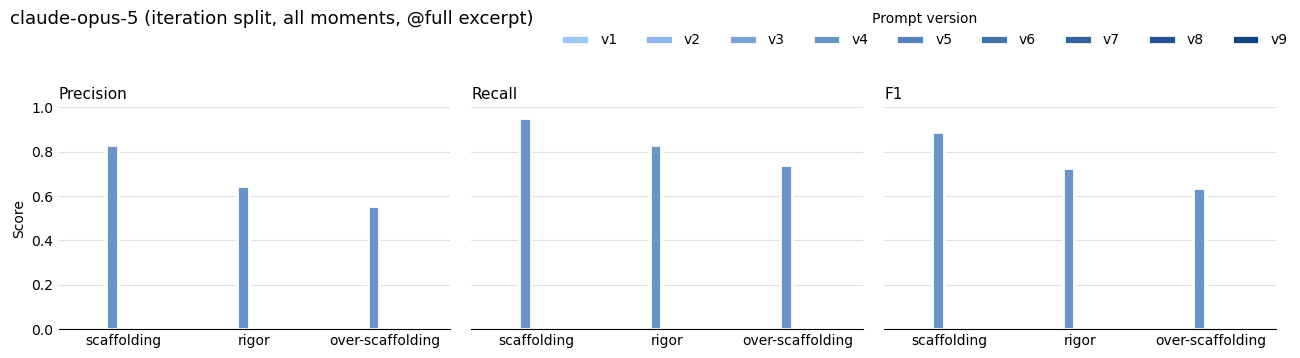

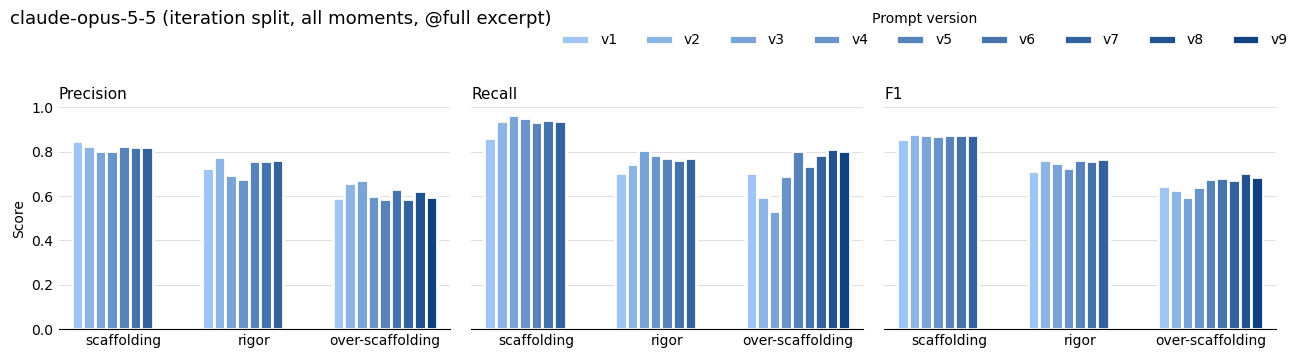

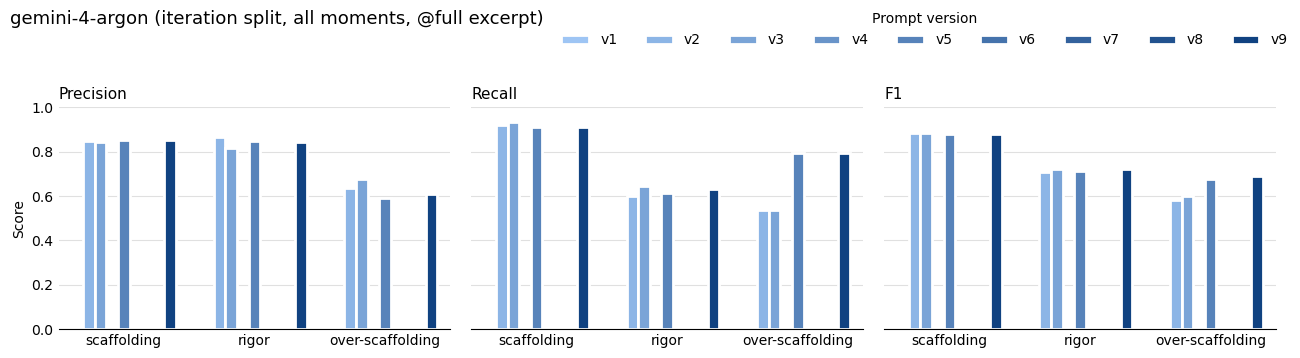

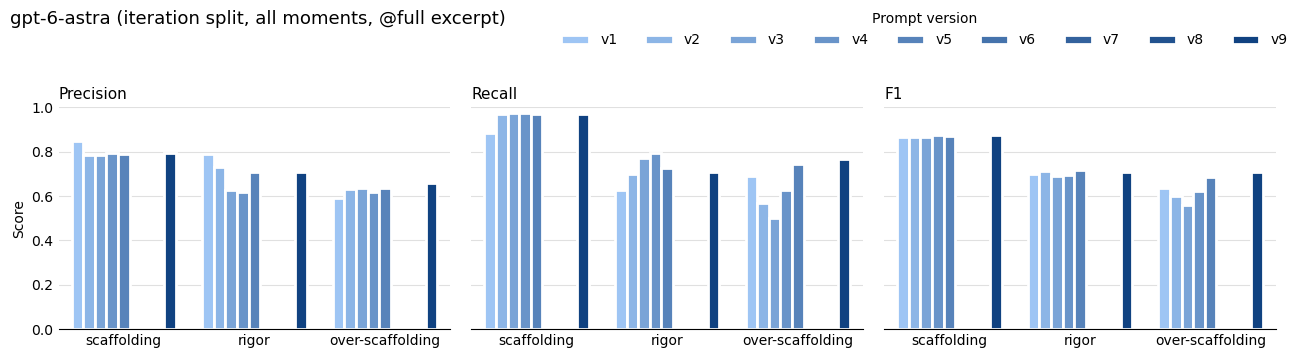

In [7]:
# plot precision, recall, and F1 as bar charts of `outputs/v2_predictions/scores.json`
import json
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import numpy as np

# Repo root, so the path resolves whether the kernel starts there or in this folder.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
SCORES_PATH = ROOT / "outputs/v2_predictions/scores.json"
SPLIT = "iteration"
BLOCK = "all"  # every moment with a usable prediction; "short" is the short-moment slice
# Excerpt width the predictions read: "full" for the whole transcript, or the
# number of dialogue turns of lead-up before the cut, e.g. "20".
CONTEXT_TURNS = "full"
METRICS = {"precision": "Precision", "recall": "Recall", "f1": "F1"}
TASKS = ["scaffolding", "rigor", "over-scaffolding"]
# Prompt versions are ordered, so they step light -> dark along one hue.
VERSION_RAMP = LinearSegmentedColormap.from_list("version", ["#9ec5f4", "#104281"])

with open(SCORES_PATH) as f:
    # A scores.json written before widths were scored has no context_turns; all
    # of those runs read the full transcript.
    scores = [
        r for r in json.load(f)
        if r["split"] == SPLIT and r.get("context_turns", "full") == CONTEXT_TURNS
    ]

# Every prompt version scored for any model, so all figures share one legend.
versions = sorted({r["prompt_version"] for r in scores}, key=int)
models = sorted({r["model"] for r in scores})


def metric_by_version(model: str, task: str, metric: str) -> list[float]:
    """The metric for each prompt version, NaN where the model has no score."""
    values = []
    for version in versions:
        record = next(
            (r for r in scores if r["model"] == model and r["prompt_version"] == version),
            None,
        )
        block = None
        if record is not None:
            block = next(t[BLOCK] for t in record["tasks"] if t["task"] == task)
        # A metric is None when undefined (e.g. precision with no predicted positives).
        value = (block or {}).get(metric)
        values.append(np.nan if value is None else value)
    return values


version_colors = {v: VERSION_RAMP(i / max(len(versions) - 1, 1)) for i, v in enumerate(versions)}

x = np.arange(len(TASKS))
bar_width = 0.8 / len(versions)

for model in models:
    fig, axes = plt.subplots(1, len(METRICS), figsize=(13, 3.6), sharey=True)
    for ax, (metric, metric_label) in zip(axes, METRICS.items()):
        for i, version in enumerate(versions):
            # Every version keeps its slot, so an unscored one leaves a gap
            # rather than shifting the others along.
            offset = (i - (len(versions) - 1) / 2) * bar_width
            ax.bar(
                x + offset,
                [metric_by_version(model, task, metric)[i] for task in TASKS],
                width=bar_width,
                color=version_colors[version],
                edgecolor="white",  # surface gap between adjacent bars
                linewidth=2,
                label=f"v{version}",
            )
        ax.set_title(metric_label, loc="left", fontsize=11)
        ax.set_xticks(x, TASKS)
        ax.set_xlim(-0.5, len(TASKS) - 0.5)  # hold unscored versions' slots open
        ax.set_ylim(0, 1)
        ax.grid(axis="y", color="#e0e0e0", linewidth=0.8)
        ax.set_axisbelow(True)
        ax.tick_params(length=0)
        for side in ("top", "right", "left"):
            ax.spines[side].set_visible(False)
    axes[0].set_ylabel("Score")
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(
        handles, labels, title="Prompt version", loc="upper right",
        ncol=len(versions), frameon=False,
    )
    fig.suptitle(
        f"{model} ({SPLIT} split, {BLOCK} moments, @{CONTEXT_TURNS} excerpt)",
        x=0.01, ha="left", fontsize=13,
    )
    fig.tight_layout(rect=(0, 0, 1, 0.9))
    plt.show()

## Full transcript vs. a lead-up window

Precision, recall, and F1 from `evaluate_scorer` at the full transcript and at a window opening `WINDOW` dialogue turns before the cut, over every moment and over the moments with few turns after the cut.

claude-opus-5-5 @full scaffolding: v7 (same template as v9)
claude-opus-5-5 @full rigor: v7 (same template as v9)


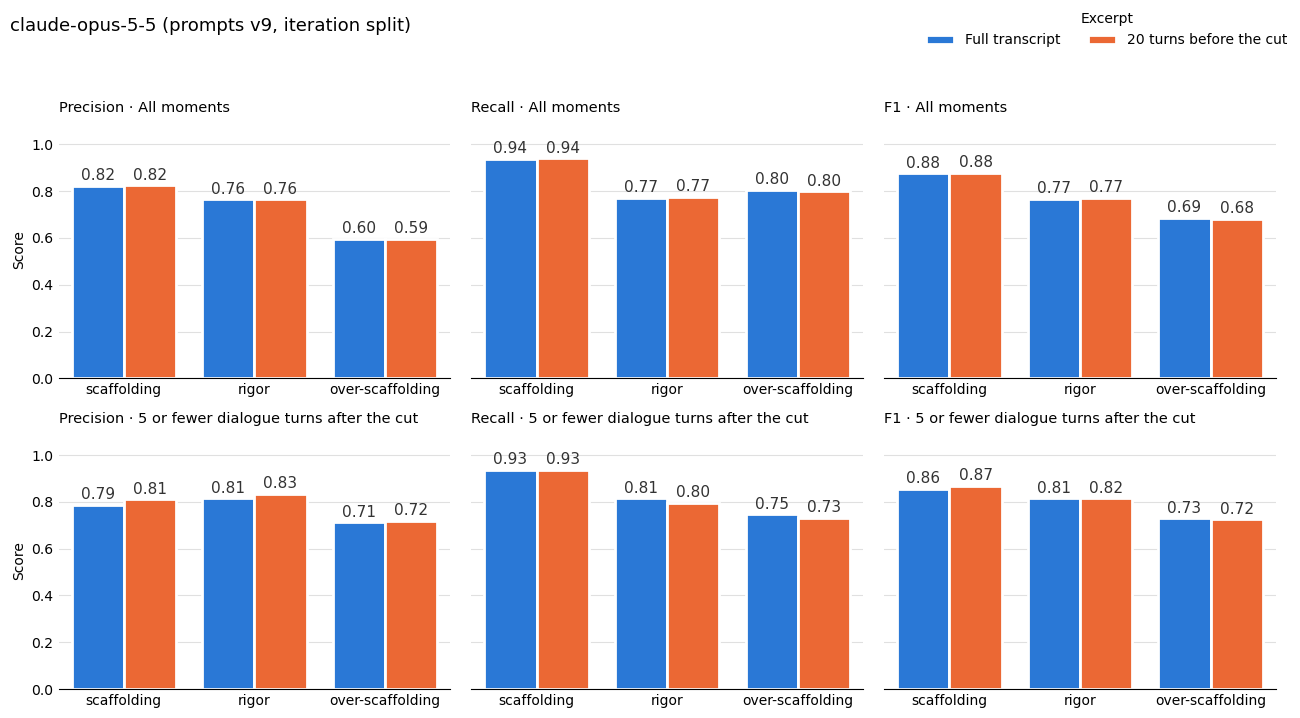

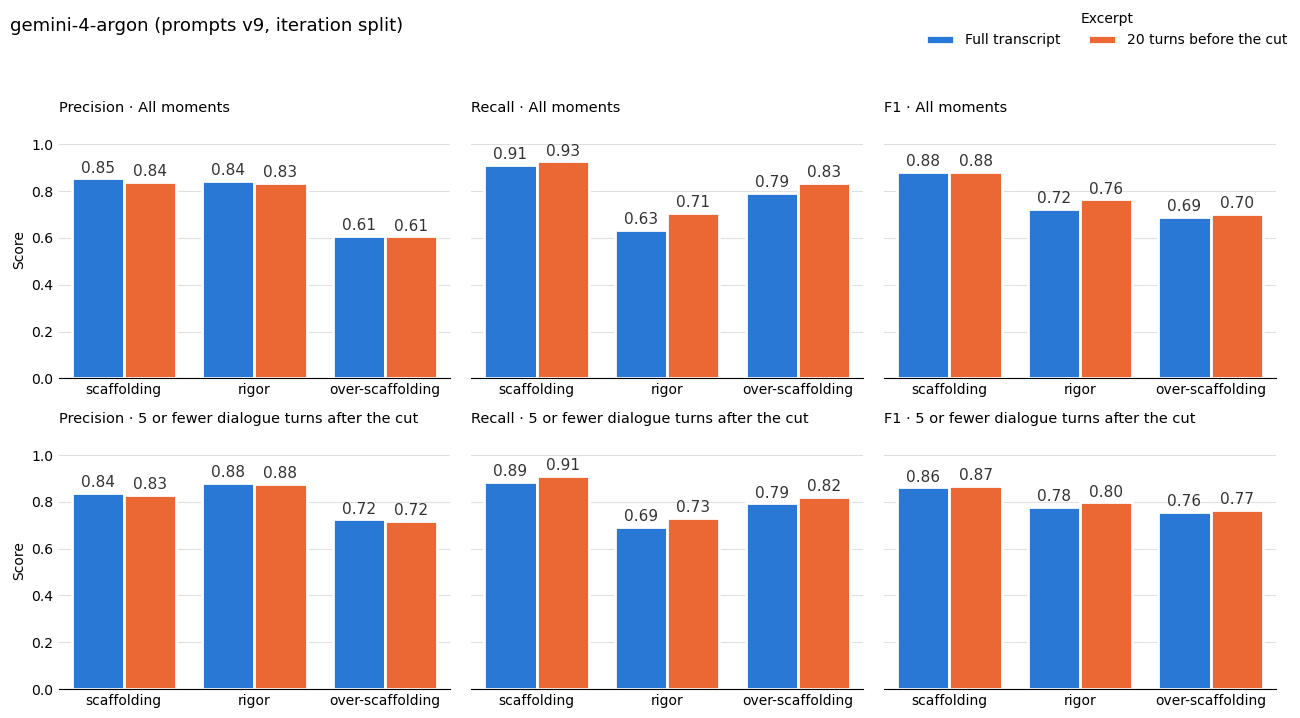

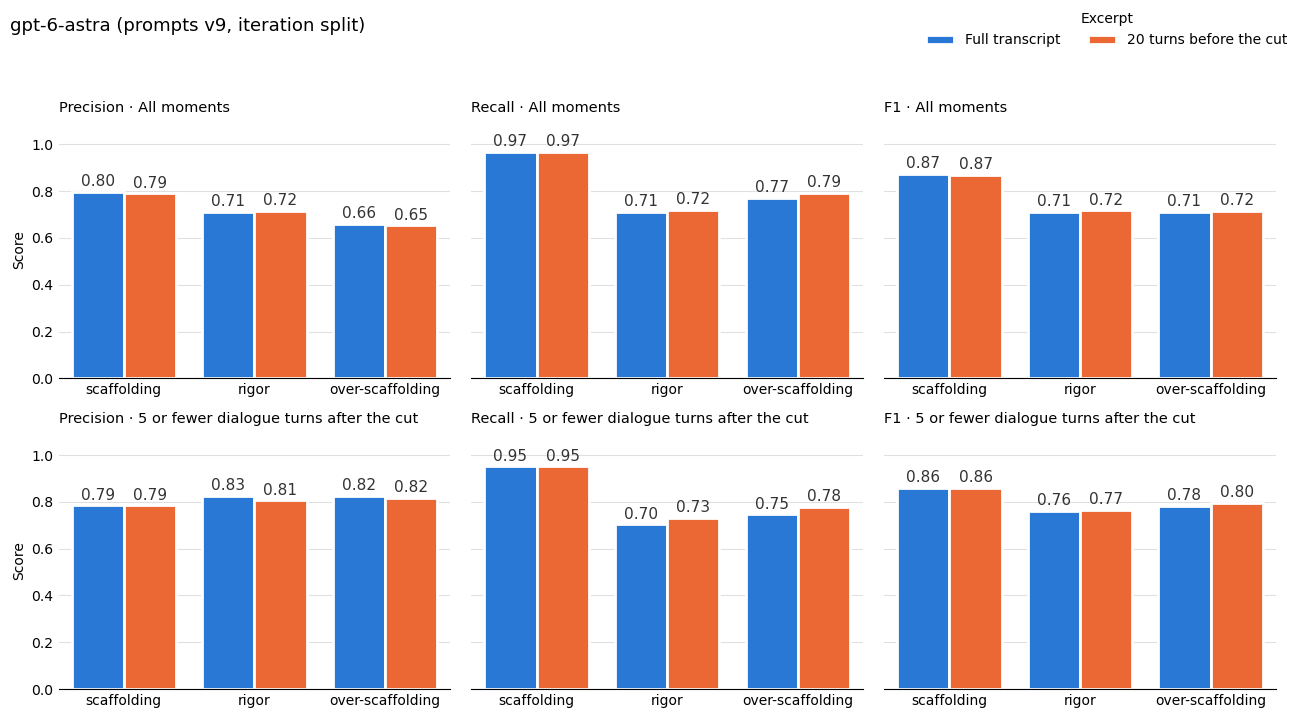

In [8]:
# Compare scores at the full transcript and a WINDOW-turn lead-up, per model,
# from `outputs/v2_predictions/scores.json` (re-run evaluate_scorer --json first).
PROMPT_DIR = ROOT / "tutormoments_build/prompts/v2"
WINDOW_VERSION = "9"
WINDOW_MODELS = ["claude-opus-5-5", "gemini-4-argon", "gpt-6-astra"]
WINDOW = "20"
WIDTH_LABELS = {"full": "Full transcript", WINDOW: f"{WINDOW} turns before the cut"}
WIDTH_COLORS = {"full": "#2a78d6", WINDOW: "#eb6834"}
# Task -> the template that predicts it.
TASK_TEMPLATES = {
    "scaffolding": "action_direction.md",
    "rigor": "action_direction.md",
    "over-scaffolding": "over-scaffolding.md",
}

with open(SCORES_PATH) as f:
    all_scores = [r for r in json.load(f) if r["split"] == SPLIT]


def template(version: str, filename: str) -> str:
    return (PROMPT_DIR / version / filename).read_text(encoding="utf-8")


def task_scores(model: str, width: str, task: str) -> tuple[str | None, dict | None]:
    """(prompt version, task row) for one model, width and task.

    Prefers WINDOW_VERSION. A round run with --passes may not have scored this
    task there, so failing that it falls back to the newest version whose
    template for the task is identical: the same template over the same
    excerpt asks the same question.
    """
    wanted = template(WINDOW_VERSION, TASK_TEMPLATES[task])
    candidates = sorted(
        (
            r for r in all_scores
            if r["model"] == model and r.get("context_turns", "full") == width
        ),
        key=lambda r: (r["prompt_version"] != WINDOW_VERSION, -int(r["prompt_version"])),
    )
    for record in candidates:
        if template(record["prompt_version"], TASK_TEMPLATES[task]) != wanted:
            continue
        row = next(t for t in record["tasks"] if t["task"] == task)
        if row["all"]["n"]:
            return record["prompt_version"], row
    return None, None


window_scores = {
    (model, width, task): task_scores(model, width, task)
    for model in WINDOW_MODELS
    for width in WIDTH_LABELS
    for task in TASKS
}
for (model, width, task), (version, _) in window_scores.items():
    if version is None:
        print(f"{model} @{width} {task}: not scored")
    elif version != WINDOW_VERSION:
        print(f"{model} @{width} {task}: v{version} (same template as v{WINDOW_VERSION})")


def block_title(block: str) -> str:
    if block == "all":
        return "All moments"
    turns = next(row["short"]["turns"] for _, row in window_scores.values() if row)
    return f"{turns} or fewer dialogue turns after the cut"


x = np.arange(len(TASKS))
bar_width = 0.8 / len(WIDTH_LABELS)
for model in WINDOW_MODELS:
    fig, axes = plt.subplots(2, len(METRICS), figsize=(13, 7.2), sharey=True)
    for row_axes, block in zip(axes, ("all", "short")):
        for ax, (metric, metric_label) in zip(row_axes, METRICS.items()):
            for i, width in enumerate(WIDTH_LABELS):
                offset = (i - (len(WIDTH_LABELS) - 1) / 2) * bar_width
                values = []
                for task in TASKS:
                    _, row = window_scores[model, width, task]
                    # A metric is None when undefined (e.g. precision with no predicted positives).
                    value = row[block].get(metric) if row else None
                    values.append(np.nan if value is None else value)
                bars = ax.bar(
                    x + offset,
                    values,
                    width=bar_width,
                    color=WIDTH_COLORS[width],
                    edgecolor="white",  # surface gap between adjacent bars
                    linewidth=2,
                    label=WIDTH_LABELS[width],
                )
                ax.bar_label(
                    bars,
                    labels=["" if np.isnan(v) else f"{v:.2f}" for v in values],
                    padding=2,
                    fontsize=11,
                    color="#333333",
                )
            ax.set_title(f"{metric_label} · {block_title(block)}", loc="left", fontsize=10.5)
            ax.set_xticks(x, TASKS)
            ax.set_xlim(-0.5, len(TASKS) - 0.5)  # hold unscored slots open
            ax.set_ylim(0, 1.1)  # headroom for the value labels
            ax.set_yticks(np.linspace(0, 1, 6))
            ax.grid(axis="y", color="#e0e0e0", linewidth=0.8)
            ax.set_axisbelow(True)
            ax.tick_params(length=0)
            for side in ("top", "right", "left"):
                ax.spines[side].set_visible(False)
        row_axes[0].set_ylabel("Score")
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(
        handles, labels, title="Excerpt", loc="upper right",
        ncol=len(WIDTH_LABELS), frameon=False,
    )
    fig.suptitle(
        f"{model} (prompts v{WINDOW_VERSION}, {SPLIT} split)", x=0.01, ha="left", fontsize=13
    )
    fig.tight_layout(rect=(0, 0, 1, 0.93))
    plt.show()